# 02 · Correlation between PV power and satellite irradiance

Inverter readings are averaged into the same 10-minute bins as the satellite averages (bin labelled by its end). A bin counts as **unconstrained** only when every reading in it was. Night bins are dropped: zero against zero would inflate every correlation.

In [1]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from common import load_joined, load_satellite, load_snapshots

TZ = "Europe/Kyiv"
plt.rcParams["figure.figsize"] = (13, 4)
plt.rcParams["axes.grid"] = True
STATE_COLORS = {
    "unconstrained": "tab:green",
    "curtailed": "tab:red",
    "unknown": "tab:orange",
    "dark": "lightgray",
}

In [2]:
joined = load_joined()
daylight = joined[
    (joined["state"] != "dark") & joined["global_tilted_irradiance"].notna()
]
unconstrained = daylight[daylight["state"] == "unconstrained"]
print(f"{len(joined)} bins, {len(daylight)} daylight, "
      f"{len(unconstrained)} unconstrained")

1502 bins, 477 daylight, 459 unconstrained


## Scatter: PV power vs GTI

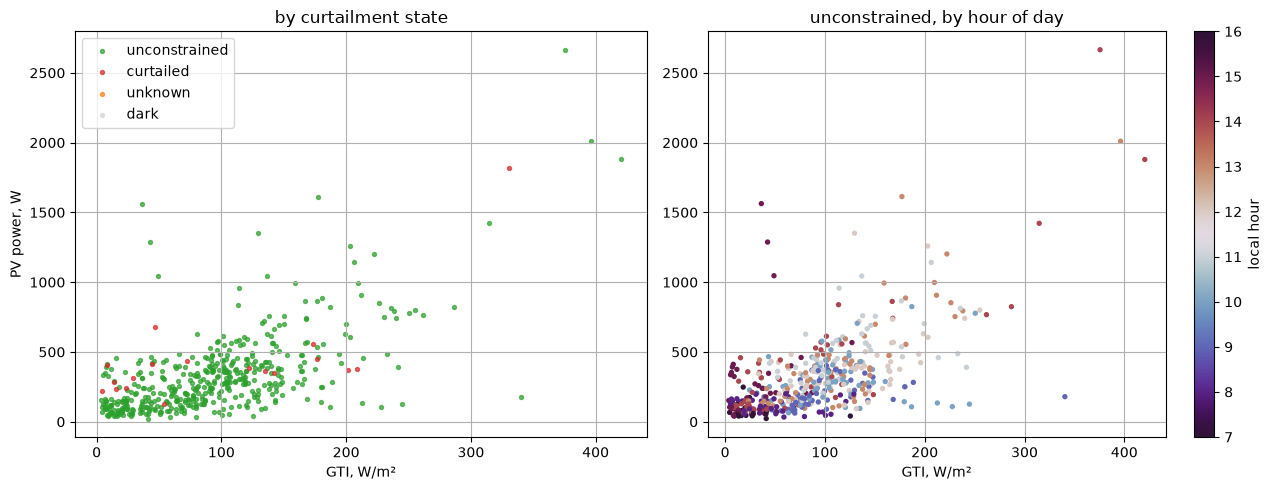

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for state, color in STATE_COLORS.items():
    part = daylight[daylight["state"] == state]
    axes[0].scatter(part["global_tilted_irradiance"], part["solar_power_w"],
                    s=8, c=color, label=state, alpha=0.7)
axes[0].set_xlabel("GTI, W/m²")
axes[0].set_ylabel("PV power, W")
axes[0].legend()
axes[0].set_title("by curtailment state")

local_hour = unconstrained.index.tz_convert(TZ).hour
sc = axes[1].scatter(unconstrained["global_tilted_irradiance"],
                     unconstrained["solar_power_w"],
                     s=8, c=local_hour, cmap="twilight_shifted")
fig.colorbar(sc, ax=axes[1], label="local hour")
axes[1].set_xlabel("GTI, W/m²")
axes[1].set_title("unconstrained, by hour of day")
fig.tight_layout()

## Which irradiance column tracks PV best?

Pearson = linear relation, Spearman = any monotonic relation.

In [4]:
columns = [
    "global_tilted_irradiance", "global_tilted_irradiance_instant",
    "shortwave_radiation", "direct_radiation", "diffuse_radiation",
    "direct_normal_irradiance", "shortwave_radiation_clear_sky",
    "terrestrial_radiation", "sunshine_duration",
]
pv = unconstrained["solar_power_w"]
pd.DataFrame({
    "pearson": unconstrained[columns].corrwith(pv),
    "spearman": unconstrained[columns].corrwith(pv, method="spearman"),
}).sort_values("pearson", ascending=False).round(3)

,pearson,spearman
global_tilted_irradiance,0.636,0.603
global_tilted_irradiance_instant,0.624,0.596
shortwave_radiation,0.558,0.608
diffuse_radiation,0.512,0.613
sunshine_duration,0.422,0.071
direct_radiation,0.358,0.214
direct_normal_irradiance,0.335,0.206
shortwave_radiation_clear_sky,0.331,0.575
terrestrial_radiation,0.330,0.575


## Linear fit through the origin

`PV = k × GTI`. `k` (W per W/m²) equals array kWp × performance ratio, e.g. k = 4 ≈ a 5 kWp array at PR 0.8.

k = 3.31 W per W/m², R² = 0.393


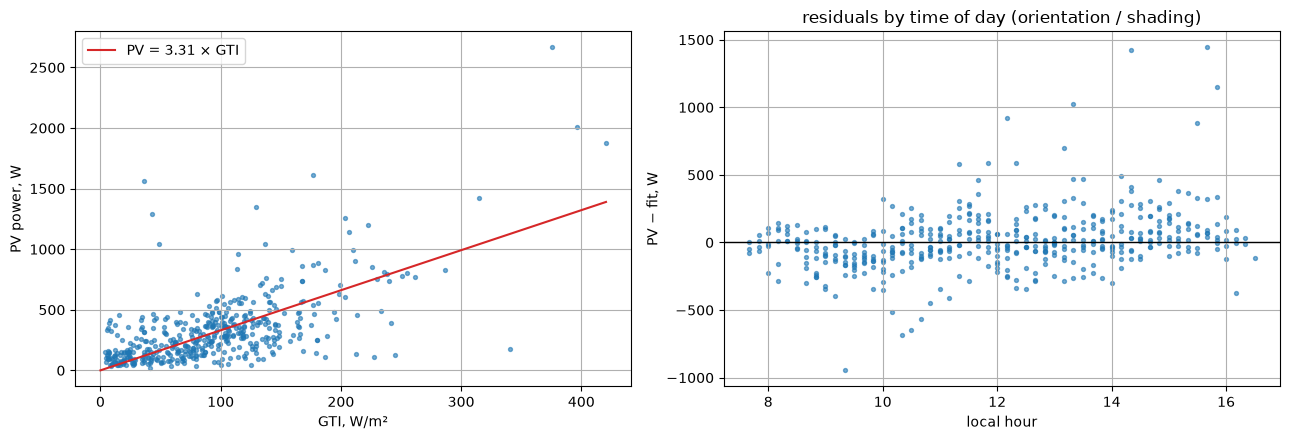

In [5]:
x = unconstrained["global_tilted_irradiance"]
k = (x * pv).sum() / (x * x).sum()
predicted = k * x
r2 = 1 - ((pv - predicted) ** 2).sum() / ((pv - pv.mean()) ** 2).sum()
print(f"k = {k:.2f} W per W/m², R² = {r2:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].scatter(x, pv, s=8, alpha=0.6)
line = np.linspace(0, x.max(), 10)
axes[0].plot(line, k * line, c="tab:red", label=f"PV = {k:.2f} × GTI")
axes[0].set_xlabel("GTI, W/m²")
axes[0].set_ylabel("PV power, W")
axes[0].legend()
residual = pv - predicted
axes[1].scatter(unconstrained.index.tz_convert(TZ).hour
                + unconstrained.index.tz_convert(TZ).minute / 60,
                residual, s=8, alpha=0.6)
axes[1].axhline(0, c="k", lw=1)
axes[1].set_xlabel("local hour")
axes[1].set_ylabel("PV − fit, W")
axes[1].set_title("residuals by time of day (orientation / shading)")
fig.tight_layout()

## Ratio PV / GTI over the day and across days

A flat ratio means GTI captures the array well. A trend through the day points to a wrong tilt/azimuth or to shading.

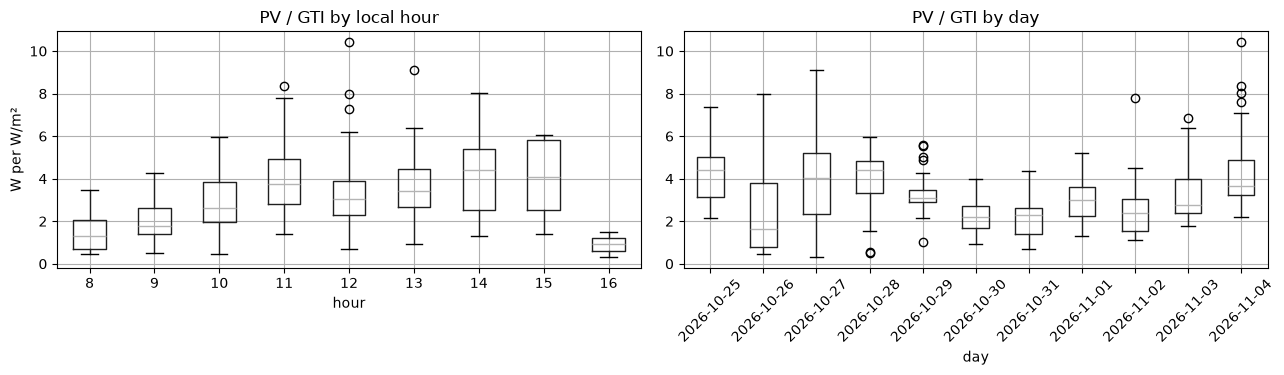

In [6]:
ratio = unconstrained.assign(
    ratio=pv / unconstrained["global_tilted_irradiance"],
    hour=unconstrained.index.tz_convert(TZ).hour,
    day=unconstrained.index.tz_convert(TZ).date,
)
ratio = ratio[ratio["global_tilted_irradiance"] > 50]
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
ratio.boxplot(column="ratio", by="hour", ax=axes[0])
axes[0].set_title("PV / GTI by local hour")
axes[0].set_ylabel("W per W/m²")
ratio.boxplot(column="ratio", by="day", ax=axes[1], rot=45)
axes[1].set_title("PV / GTI by day")
fig.suptitle("")
fig.tight_layout()

## Time alignment: lag scan

Interpolate instantaneous GTI at each 1-minute unconstrained reading shifted by a lag. The best lag should be near 0; a big offset means a time-zone or averaging mistake.

Text(0.5, 1.0, 'best lag: 5 min')

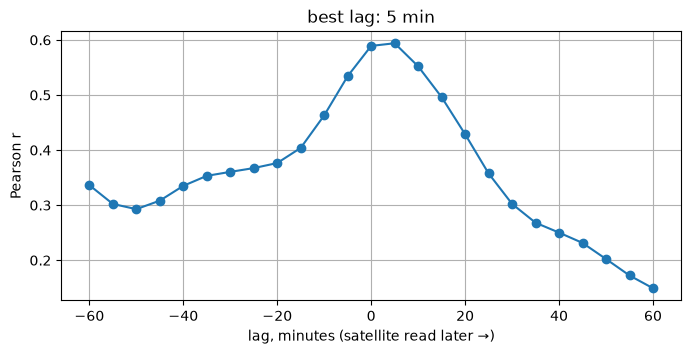

In [7]:
snapshots = load_snapshots()
raw = snapshots[snapshots["state"] == "unconstrained"]
gti = load_satellite()["global_tilted_irradiance_instant"].dropna()
gti_seconds = gti.index.astype("int64") / 1e9
lags = range(-60, 61, 5)
scores = []
for lag in lags:
    t = (raw.index + pd.Timedelta(minutes=lag)).astype("int64") / 1e9
    values = np.interp(t, gti_seconds, gti.values)
    scores.append(np.corrcoef(values, raw["solar_power_w"])[0, 1])
plt.figure(figsize=(8, 3.5))
plt.plot(list(lags), scores, marker="o")
plt.xlabel("lag, minutes (satellite read later →)")
plt.ylabel("Pearson r")
best = list(lags)[int(np.argmax(scores))]
plt.title(f"best lag: {best} min")

## What else explains the misfit?

Residuals against battery charge, grid voltage (outages) and load. A pattern here means some 'unconstrained' bins are still limited by the load.

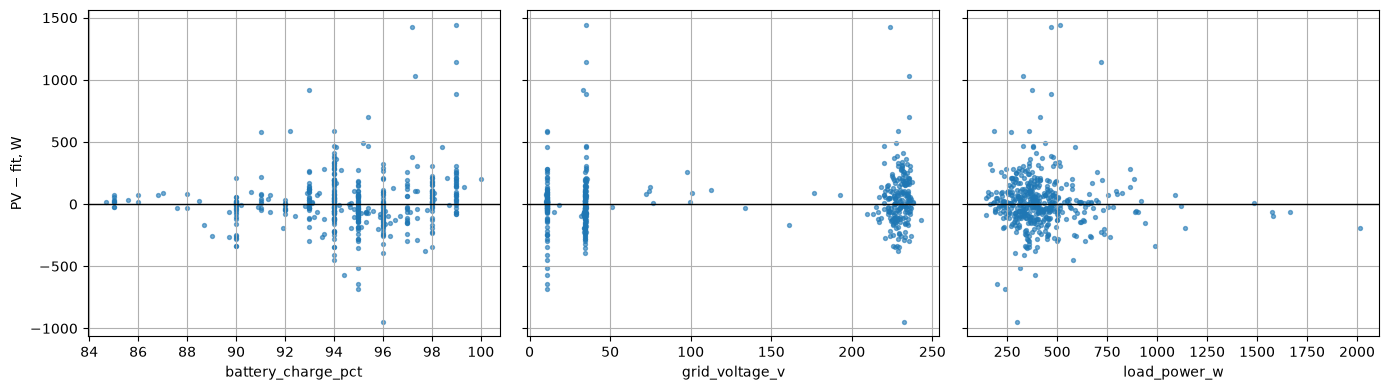

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
for ax, col in zip(axes, ["battery_charge_pct", "grid_voltage_v",
                          "load_power_w"]):
    ax.scatter(unconstrained[col], residual, s=8, alpha=0.6)
    ax.axhline(0, c="k", lw=1)
    ax.set_xlabel(col)
axes[0].set_ylabel("PV − fit, W")
fig.tight_layout()